In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split

X_test_enc = pd.read_csv('../data/X_test_enc.csv')
y_test = pd.read_csv('../data/y_test.csv').squeeze().to_numpy()
sex_test = pd.read_csv('../data/sex_test.csv').squeeze().to_numpy()

xgb_calibrated = joblib.load('../src/xgb_calibrated_model.pkl')

RECOMMENDED_THRESHOLD = 0.20
probs = xgb_calibrated.predict_proba(X_test_enc)[:, 1]
preds = (probs >= RECOMMENDED_THRESHOLD).astype(int)

print(len(sex_test), len(y_test), len(preds), "| rejected:", preds.sum())

200 200 200 | rejected: 125


In [2]:
df_full = pd.read_csv('../data/german_credit_clean.csv')
X = df_full.drop(columns=['default', 'sex'])
y = df_full['default']

_, X_test_raw, _, y_test_chk = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Fail loudly if the split doesn't reproduce exactly
assert (y_test_chk.to_numpy() == y_test).all(), "Split mismatch!"
assert (X_test_raw.index.to_series().map(df_full['sex']).to_numpy() == sex_test).all(), "Sex labels misaligned!"

age_test = X_test_raw['age'].to_numpy()
foreign_worker_test = X_test_raw['foreign_worker'].to_numpy()

age_median = np.median(age_test)
age_group = np.where(age_test <= age_median, 'young', 'old')

print("Age median split point:", age_median)
print(pd.Series(age_group).value_counts().to_dict())
print(pd.Series(foreign_worker_test).value_counts().to_dict())
print(pd.Series(sex_test).value_counts().to_dict())

Age median split point: 33.0
{'young': 101, 'old': 99}
{'yes': 194, 'no': 6}
{'male': 139, 'female': 61}


In [3]:
def approval_rates(preds, groups):
    return {g: float((preds[groups == g] == 0).mean()) for g in pd.unique(groups)}

def report_di(name, preds, groups, caution=''):
    rates = approval_rates(preds, groups)
    di = min(rates.values()) / max(rates.values())
    flag = 'FLAGGED (<0.8)' if di < 0.8 else 'within 80% rule'
    print(f"=== {name} ===\n{rates}\nDisparate Impact Ratio: {di:.3f} {flag} {caution}\n")
    return di

di_sex = report_di('SEX', preds, sex_test)
di_age = report_di('AGE GROUP', preds, age_group)
di_fw = report_di('FOREIGN WORKER', preds, foreign_worker_test, '(CAUTION: n=6 in minority group)')

=== SEX ===
{'male': 0.4028776978417266, 'female': 0.3114754098360656}
Disparate Impact Ratio: 0.773 FLAGGED (<0.8) 

=== AGE GROUP ===
{np.str_('old'): 0.48484848484848486, np.str_('young'): 0.26732673267326734}
Disparate Impact Ratio: 0.551 FLAGGED (<0.8) 

=== FOREIGN WORKER ===
{'yes': 0.36082474226804123, 'no': 0.8333333333333334}
Disparate Impact Ratio: 0.433 FLAGGED (<0.8) (CAUTION: n=6 in minority group)



In [4]:
def group_rates(y_true, y_pred, groups):
    rows = {}
    for g in pd.unique(groups):
        m = groups == g
        yt, yp = y_true[m], y_pred[m]
        tp = ((yp == 1) & (yt == 1)).sum(); fn = ((yp == 0) & (yt == 1)).sum()
        fp = ((yp == 1) & (yt == 0)).sum(); tn = ((yp == 0) & (yt == 0)).sum()
        rows[g] = {'TPR (recall)': tp / (tp + fn) if (tp + fn) else np.nan,
                   'FPR': fp / (fp + tn) if (fp + tn) else np.nan,
                   'n': int(m.sum())}
    return pd.DataFrame(rows).T

for name, groups in [('SEX', sex_test), ('AGE GROUP', age_group), ('FOREIGN WORKER', foreign_worker_test)]:
    print(f"=== TPR/FPR by {name} ===")
    print(group_rates(y_test, preds, groups), "\n")

=== TPR/FPR by SEX ===
        TPR (recall)       FPR      n
male           0.875  0.484848  139.0
female         0.900  0.585366   61.0 

=== TPR/FPR by AGE GROUP ===
       TPR (recall)       FPR      n
old        0.842105  0.437500   99.0
young      0.902439  0.616667  101.0 

=== TPR/FPR by FOREIGN WORKER ===
     TPR (recall)       FPR      n
yes      0.881356  0.533333  194.0
no       1.000000  0.000000    6.0 



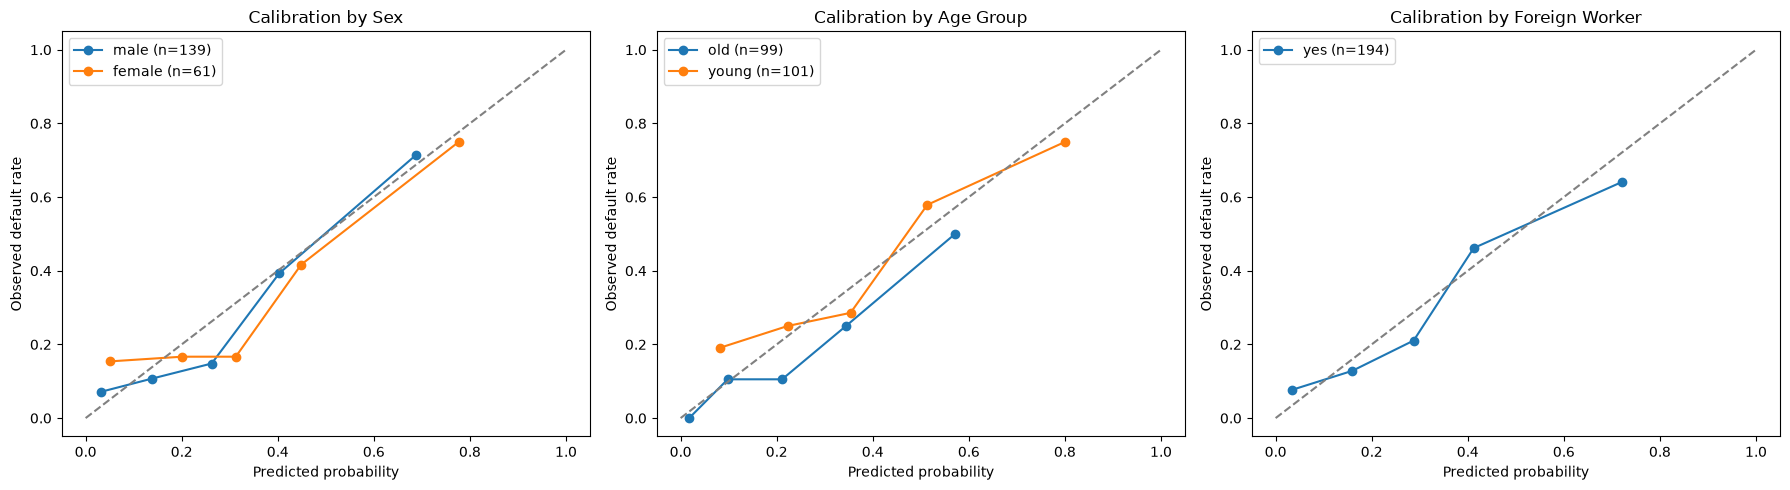

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, groups, title in zip(axes, [sex_test, age_group, foreign_worker_test],
                             ['Sex', 'Age Group', 'Foreign Worker']):
    for g in pd.unique(groups):
        m = groups == g
        if m.sum() < 10:
            continue   # too few points for a meaningful curve
        prob_true, prob_pred = calibration_curve(y_test[m], probs[m], n_bins=5, strategy='quantile')
        ax.plot(prob_pred, prob_true, marker='o', label=f'{g} (n={m.sum()})')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
    ax.set_title(f'Calibration by {title}')
    ax.set_xlabel('Predicted probability')
    ax.set_ylabel('Observed default rate')
    ax.legend()

plt.tight_layout()
plt.savefig('../reports/figures/fairness_calibration_by_group.png', dpi=100)
plt.show()

In [6]:
rng = np.random.default_rng(42)
n = len(y_test)
fpr_gap_age, di_age_boot = [], []

for _ in range(2000):
    idx = rng.integers(0, n, n)
    yt, yp, ag = y_test[idx], preds[idx], age_group[idx]
    try:
        fpr = {g: ((yp[ag == g] == 1) & (yt[ag == g] == 0)).sum() / (yt[ag == g] == 0).sum()
               for g in ('young', 'old')}
        appr = {g: (yp[ag == g] == 0).mean() for g in ('young', 'old')}
    except ZeroDivisionError:
        continue
    fpr_gap_age.append(fpr['young'] - fpr['old'])
    di_age_boot.append(min(appr.values()) / max(appr.values()))

print("Age FPR gap (young - old), 95% CI:", np.percentile(fpr_gap_age, [2.5, 97.5]).round(3))
print("Age disparate impact ratio, 95% CI:", np.percentile(di_age_boot, [2.5, 97.5]).round(3))

Age FPR gap (young - old), 95% CI: [0.028 0.33 ]
Age disparate impact ratio, 95% CI: [0.374 0.784]
